<a href="https://colab.research.google.com/github/VictorGMSS/Otimizando-modelos-de-machine-learning/blob/main/Otimizando_modelos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importando bibliotecas

In [ ]:
!pip install scikit-optimize

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 1.2 MB/s eta 0:00:00


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
import numpy as np
from sklearn.model_selection import StratifiedKFold
import matplotlib.pyplot as plt
from numpy import linspace
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import RandomizedSearchCV
from skopt.space import Real, Integer, Categorical
from skopt import BayesSearchCV

# Conhecendo os dados


In [ ]:
df = pd.read_csv("https://raw.githubusercontent.com/VictorGMSS/Otimizando-modelos-de-machine-learning/refs/heads/main/dados_inadimplencia.csv")
df.head()

,receita_cliente,anuidade_emprestimo,anos_casa_propria,telefone_trab,avaliacao_cidade,score_1,score_2,score_3,score_social,troca_telefone,inadimplente
0,16855.246324,2997.000000,12.157324,0,2.0,0.501213,0.003109,0.513171,0.117428,243.0,1
1,13500.000000,2776.050000,12.157324,0,2.0,0.501213,0.269730,0.513171,0.097900,617.0,0
2,11250.000000,2722.188351,12.157324,0,3.0,0.701396,0.518625,0.700184,0.118600,9.0,0
3,27000.000000,6750.000000,3.000000,0,2.0,0.501213,0.649571,0.513171,0.047400,300.0,0
4,22500.000000,3097.800000,12.157324,0,2.0,0.440744,0.509677,0.513171,0.014400,2913.0,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14578 entries, 0 to 14577
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   receita_cliente      14578 non-null  float64
 1   anuidade_emprestimo  14578 non-null  float64
 2   anos_casa_propria    14578 non-null  float64
 3   telefone_trab        14578 non-null  int64  
 4   avaliacao_cidade     14578 non-null  float64
 5   score_1              14578 non-null  float64
 6   score_2              14578 non-null  float64
 7   score_3              14578 non-null  float64
 8   score_social         14578 non-null  float64
 9   troca_telefone       14578 non-null  float64
 10  inadimplente         14578 non-null  int64  
dtypes: float64(9), int64(2)
memory usage: 1.2 MB


In [ ]:
df['inadimplente'].value_counts()

,count
inadimplente,
0,9862
1,4716


# Preparando os dados

In [ ]:
round(df['inadimplente'].value_counts(normalize=True)*100, 2)

,proportion
inadimplente,
0,67.65
1,32.35


In [ ]:
x = df.drop('inadimplente', axis=1)
y = df['inadimplente']

In [ ]:
RANDOM_STATE = 42

x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.33, random_state=RANDOM_STATE)

# Construindo os modelos


## Decision tree classifier

In [ ]:
modelo_dt = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
modelo_dt.fit(x_treino, y_treino)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [ ]:
recall_dt = recall_score(y_teste, modelo_dt.predict(x_teste))
print(f"Reacall do DT = {recall_dt:.3f}")

Reacall do DT = 0.143


## Regressão logística

In [ ]:
logistic_pipeline = make_pipeline(StandardScaler(), LogisticRegression())
logistic_pipeline.fit(x_treino, y_treino)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression())])

In [ ]:
recall_lr = recall_score(y_teste, logistic_pipeline.predict(x_teste))
print(f"Reacall do lr = {recall_lr:.3f}")

Reacall do lr = 0.236


# Realizando a busca em grade


## DecisionTreeClassifier

In [ ]:

param_grid_dt = {
    'criterion':  ['gini', 'entropy'],
    'max_depth': np.linspace(6, 12, 4, dtype=int),
    'min_samples_split': np.linspace(5, 20, 4, dtype=int),
    'min_samples_leaf': np.linspace(5, 20, 4, dtype=int),
    'max_features': ['sqrt', 'log2'],
    'splitter': ['best', 'random']
}

In [ ]:
cv = StratifiedKFold(shuffle=True, random_state=RANDOM_STATE)

dt_grid_search = GridSearchCV(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
             param_grid=param_grid_dt,
             scoring="recall",
             n_jobs=-1,
             cv=cv)

dt_grid_search.fit(x_treino, y_treino)


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=DecisionTreeClassifier(random_state=42), n_jobs=-1,
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': array([ 6,  8, 10, 12]),
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_leaf': array([ 5, 10, 15, 20]),
                         'min_samples_split': array([ 5, 10, 15, 20]),
                         'splitter': ['best', 'random']},
             scoring='recall')

## Obtendo informações da busca em grade

In [ ]:
dt_grid_search.best_params_

{'criterion': 'entropy',
 'max_depth': np.int64(12),
 'max_features': 'sqrt',
 'min_samples_leaf': np.int64(5),
 'min_samples_split': np.int64(20),
 'splitter': 'best'}

In [ ]:
df_cv_results_dt = pd.DataFrame(dt_grid_search.cv_results_)
df_cv_results_dt.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_criterion,param_max_depth,param_max_features,param_min_samples_leaf,param_min_samples_split,param_splitter,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.013908,0.001230,0.005062,0.000283,gini,6,sqrt,5,5,best,"{'criterion': 'gini', 'max_depth': 6, 'max_fea...",0.156300,0.161085,0.212121,0.298722,0.207668,0.207179,0.051221,177
1,0.004598,0.000712,0.003640,0.000178,gini,6,sqrt,5,5,random,"{'criterion': 'gini', 'max_depth': 6, 'max_fea...",0.130781,0.154705,0.167464,0.130990,0.162939,0.149376,0.015642,437
2,0.013130,0.000792,0.005059,0.001516,gini,6,sqrt,5,10,best,"{'criterion': 'gini', 'max_depth': 6, 'max_fea...",0.156300,0.161085,0.212121,0.298722,0.207668,0.207179,0.051221,177
3,0.004797,0.000503,0.004530,0.001558,gini,6,sqrt,5,10,random,"{'criterion': 'gini', 'max_depth': 6, 'max_fea...",0.130781,0.154705,0.167464,0.130990,0.162939,0.149376,0.015642,437
4,0.012758,0.000976,0.004995,0.000806,gini,6,sqrt,5,15,best,"{'criterion': 'gini', 'max_depth': 6, 'max_fea...",0.157895,0.161085,0.199362,0.290735,0.214058,0.204627,0.048189,195


In [ ]:
df_cv_results_dt.loc[[dt_grid_search.best_index_]]

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_criterion,param_max_depth,param_max_features,param_min_samples_leaf,param_min_samples_split,param_splitter,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
454,0.024736,0.002006,0.007062,0.005381,entropy,12,sqrt,5,20,best,"{'criterion': 'entropy', 'max_depth': 12, 'max...",0.282297,0.295056,0.341308,0.247604,0.364217,0.306096,0.041779,1


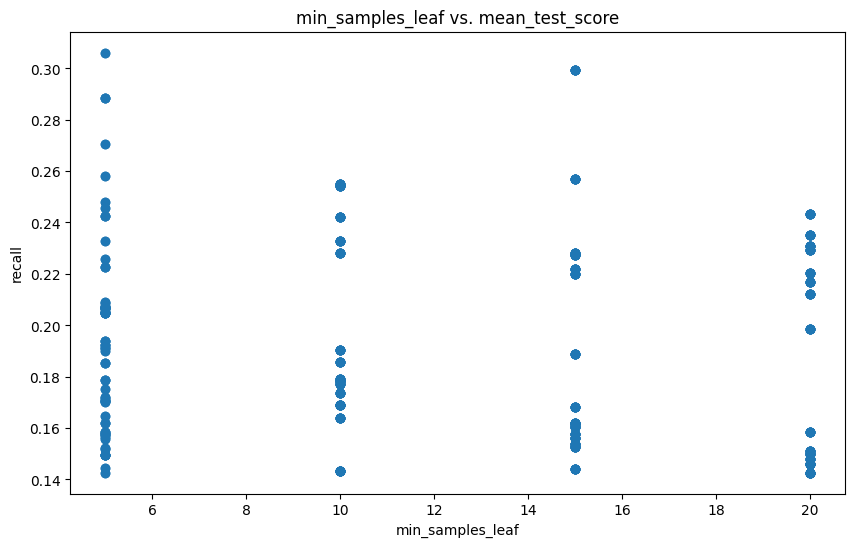

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(
    df_cv_results_dt['param_min_samples_leaf'],
    df_cv_results_dt['mean_test_score'],
    )

plt.title('min_samples_leaf vs. mean_test_score')
plt.xlabel('min_samples_leaf')
plt.ylabel('recall')
plt.show()

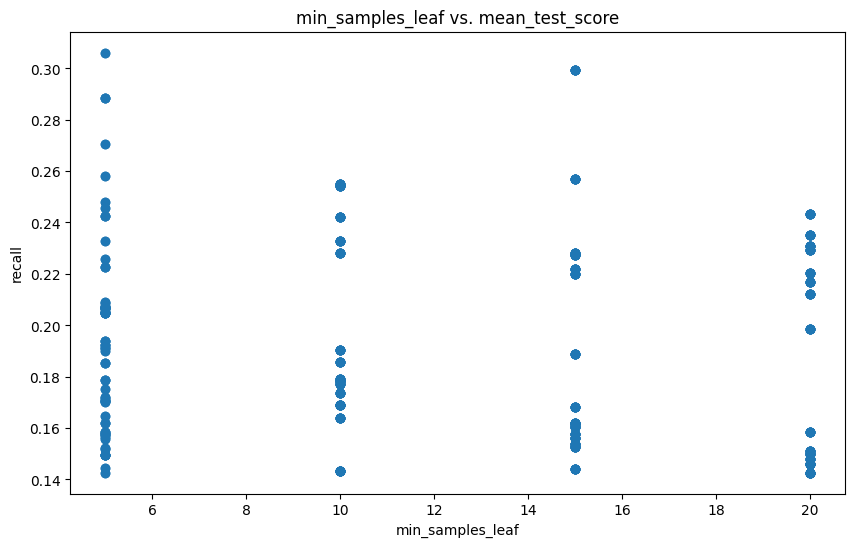

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(
    df_cv_results_dt['param_min_samples_leaf'],
    df_cv_results_dt['mean_test_score'],
    )

plt.title('min_samples_leaf vs. mean_test_score')
plt.xlabel('min_samples_leaf')
plt.ylabel('recall')
plt.show()

## Busca em grade para o LogisticRegression

In [ ]:
max_iter = np.linspace(100, 300, 5, dtype=int)
c = [0.001, 0.01, 0.1, 1, 10]

param_grid_lr = [

    {'logisticregression__solver' : ['newton-cg', 'lbfgs'],
      'logisticregression__penalty' : ['l2'],
      'logisticregression__max_iter' : max_iter,
       'logisticregression__C' : c},
    {'logisticregression__solver' : ['liblinear'],
      'logisticregression__penalty' : ['l1', 'l2'],
      'logisticregression__max_iter' : max_iter,
      'logisticregression__C' : c},
]

In [ ]:
lr_grid_search = GridSearchCV(estimator = make_pipeline(StandardScaler(), LogisticRegression()),
                              param_grid = param_grid_lr,
                              scoring = "recall",
                              n_jobs = -1,
                              cv = cv)

lr_grid_search.fit(x_treino, y_treino)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('standardscaler', StandardScaler()),
                                       ('logisticregression',
                                        LogisticRegression())]),
             n_jobs=-1,
             param_grid=[{'logisticregression__C': [0.001, 0.01, 0.1, 1, 10],
                          'logisticregression__max_iter': array([100, 150, 200, 250, 300]),
                          'logisticregression__penalty': ['l2'],
                          'logisticregression__solver': ['newton-cg', 'lbfgs']},
                         {'logisticregression__C': [0.001, 0.01, 0.1, 1, 10],
                          'logisticregression__max_iter': array([100, 150, 200, 250, 300]),
                          'logisticregression__penalty': ['l1', 'l2'],
                          'logisticregression__solver': ['liblinear']}],
             scoring='recall')

In [ ]:
lr_grid_search.best_params_

{'logisticregression__C': 0.001,
 'logisticregression__max_iter': np.int64(100),
 'logisticregression__penalty': 'l2',
 'logisticregression__solver': 'liblinear'}

In [ ]:
df_cv_results_lr = pd.DataFrame(lr_grid_search.cv_results_)
df_cv_results_lr.head()

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_logisticregression__C,param_logisticregression__max_iter,param_logisticregression__penalty,param_logisticregression__solver,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.017039,0.002742,0.005787,0.000163,0.001,100,l2,newton-cg,"{'logisticregression__C': 0.001, 'logisticregr...",0.100478,0.116427,0.089314,0.099042,0.083067,0.097666,0.011355,86
1,0.011357,0.001310,0.006172,0.001196,0.001,100,l2,lbfgs,"{'logisticregression__C': 0.001, 'logisticregr...",0.100478,0.116427,0.089314,0.099042,0.083067,0.097666,0.011355,86
2,0.020742,0.008761,0.007036,0.001911,0.001,150,l2,newton-cg,"{'logisticregression__C': 0.001, 'logisticregr...",0.100478,0.116427,0.089314,0.099042,0.083067,0.097666,0.011355,86
3,0.009647,0.000363,0.005330,0.000097,0.001,150,l2,lbfgs,"{'logisticregression__C': 0.001, 'logisticregr...",0.100478,0.116427,0.089314,0.099042,0.083067,0.097666,0.011355,86
4,0.013981,0.000385,0.005488,0.000182,0.001,200,l2,newton-cg,"{'logisticregression__C': 0.001, 'logisticregr...",0.100478,0.116427,0.089314,0.099042,0.083067,0.097666,0.011355,86


In [ ]:
df_cv_results_lr.loc[[lr_grid_search.best_index_]]

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_logisticregression__C,param_logisticregression__max_iter,param_logisticregression__penalty,param_logisticregression__solver,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
51,0.012358,0.000778,0.005066,0.000105,0.001,100,l2,liblinear,"{'logisticregression__C': 0.001, 'logisticregr...",0.267943,0.271132,0.271132,0.238019,0.230032,0.255652,0.017875,1


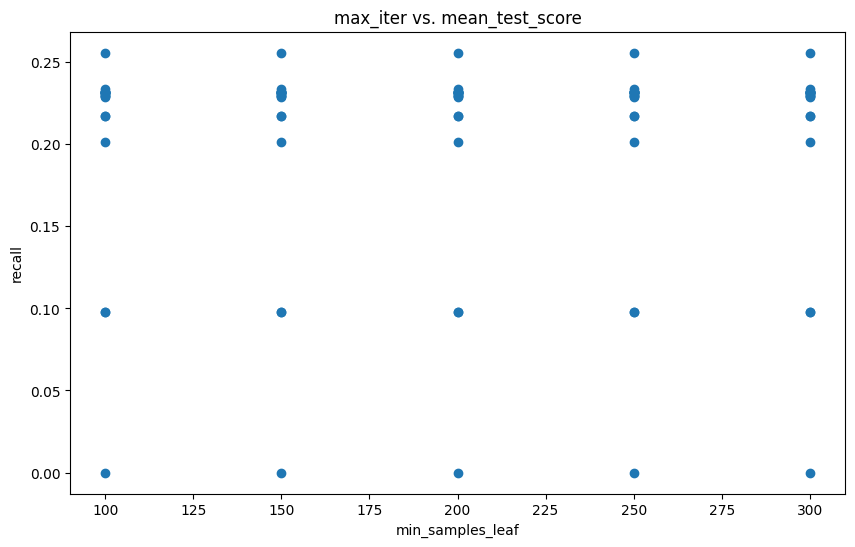

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(
    df_cv_results_lr['param_logisticregression__max_iter'],
    df_cv_results_lr['mean_test_score'],
    )

plt.title('max_iter vs. mean_test_score')
plt.xlabel('min_samples_leaf')
plt.ylabel('recall')
plt.show()

## Busca em grade para o KNN

In [ ]:
param_grid_knn = {
    'knn__n_neighbors': linspace(5, 25, 10, dtype=int),
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan']
}

In [ ]:
pipe_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

knn_grid_search = GridSearchCV(estimator = pipe_knn,
                               param_grid = param_grid_knn,
                               scoring = "recall",
                               n_jobs = -1,
                               cv = cv)

knn_grid_search.fit(x_treino, y_treino)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('knn', KNeighborsClassifier())]),
             n_jobs=-1,
             param_grid={'knn__metric': ['euclidean', 'manhattan'],
                         'knn__n_neighbors': array([ 5,  7,  9, 11, 13, 16, 18, 20, 22, 25]),
                         'knn__weights': ['uniform', 'distance']},
             scoring='recall')

In [ ]:
knn_grid_search.best_params_

{'knn__metric': 'manhattan',
 'knn__n_neighbors': np.int64(5),
 'knn__weights': 'distance'}

In [ ]:
df_cv_results_knn = pd.DataFrame(knn_grid_search.cv_results_)

df_cv_results_knn.loc[[knn_grid_search.best_index_]]

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_knn__metric,param_knn__n_neighbors,param_knn__weights,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
21,0.017773,0.000843,0.424339,0.006403,manhattan,5,distance,"{'knn__metric': 'manhattan', 'knn__n_neighbors...",0.365231,0.368421,0.379585,0.341853,0.373802,0.365779,0.012921,1


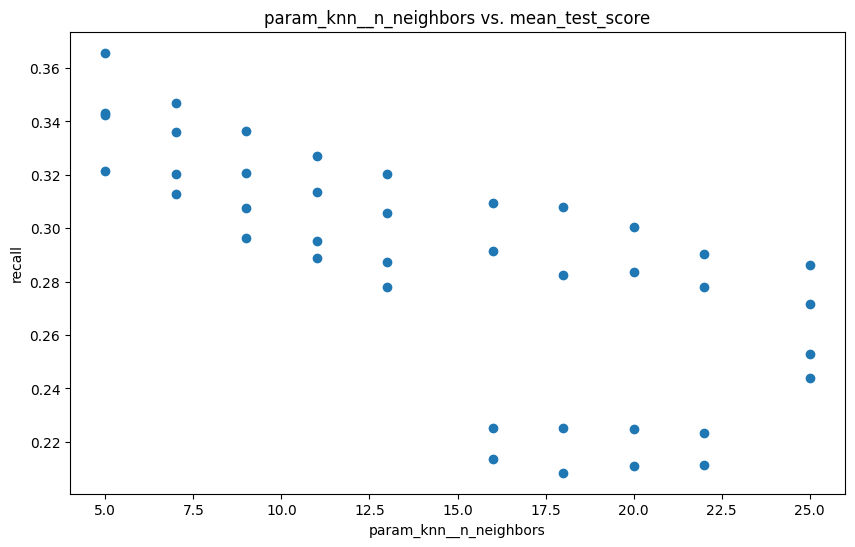

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(
    df_cv_results_knn['param_knn__n_neighbors'],
    df_cv_results_knn['mean_test_score'],
    )

plt.title('param_knn__n_neighbors vs. mean_test_score')
plt.xlabel('param_knn__n_neighbors')
plt.ylabel('recall')
plt.show()

# Validação cruzada aninhada

## Decision Tree Classifier

In [ ]:
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

outer_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

In [ ]:
dt_nested_gs = GridSearchCV(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
             param_grid=param_grid_dt,
             scoring="recall",
             n_jobs=-1,
             cv=inner_cv)

dt_nested_scores = cross_val_score(dt_nested_gs, x_treino, y_treino, cv=outer_cv)


In [ ]:
print(f'resultado de cada iteração do cv externo: {dt_nested_scores}')
print(f'média: {dt_nested_scores.mean()}')

dt_nested_gs.fit(x_treino, y_treino)
best_params = dt_nested_gs.best_params_
print("Melhores hiperparâmetros:", best_params)

resultado de cada iteração do cv externo: [0.26889952 0.18199234 0.25670498]
média: 0.23586561317958776
Melhores hiperparâmetros: {'criterion': 'entropy', 'max_depth': np.int64(12), 'max_features': 'sqrt', 'min_samples_leaf': np.int64(5), 'min_samples_split': np.int64(20), 'splitter': 'best'}


## LogisticRegression

In [ ]:
max_iter = np.linspace(100, 300, 5, dtype=int)
c = [0.001, 0.01, 0.1, 1, 10]

param_grid_lr = [
    {'logisticregression__solver' : ['newton-cg', 'lbfgs'],
      'logisticregression__penalty' : ['l2'],
      'logisticregression__max_iter' : max_iter,
       'logisticregression__C' : c},
    {'logisticregression__solver' : ['liblinear'],
      'logisticregression__penalty' : ['l1', 'l2'],
      'logisticregression__max_iter' : max_iter,
      'logisticregression__C' : c},
]

inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
outer_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

lr_nested_gs = GridSearchCV(estimator = make_pipeline(StandardScaler(), LogisticRegression()),
                               param_grid = param_grid_lr,
                               scoring = "recall",
                               n_jobs = -1,
                               cv = inner_cv)

lr_nested_scores = cross_val_score(lr_nested_gs, x_treino, y_treino, cv=outer_cv)

In [ ]:
print("Métricas de desempenho para cada iteração do CV externo:", lr_nested_scores)
print(f"Média das métricas de desempenho do CV externo: {lr_nested_scores.mean():.4f}") # melhorar esse texto para se referenciar somente a métrica recall

lr_nested_gs.fit(x_treino, y_treino)
best_params = lr_nested_gs.best_params_
print("Melhores hiperparâmetros:", best_params)

Métricas de desempenho para cada iteração do CV externo: [0.26985646 0.26245211 0.2394636 ]
Média das métricas de desempenho do CV externo: 0.2573
Melhores hiperparâmetros: {'logisticregression__C': 0.001, 'logisticregression__max_iter': np.int64(100), 'logisticregression__penalty': 'l2', 'logisticregression__solver': 'liblinear'}


# Busca aleatória

## Decision Tree Classifier

In [ ]:
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

outer_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

rs_dt = RandomizedSearchCV(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
            param_distributions=param_grid_dt,
            n_iter=100,
            scoring='recall',
            n_jobs=-1,
            cv=inner_cv,
            random_state=RANDOM_STATE)

rs_dt_nested_scores = cross_val_score(rs_dt, x_treino, y_treino, cv=outer_cv)

In [ ]:
print(f'resultado de cada iteração do cv externo: {rs_dt_nested_scores}')
print(f'média: {rs_dt_nested_scores.mean()}')

rs_dt.fit(x_treino, y_treino)
best_params = rs_dt.best_params_
print("Melhores hiperparâmetros:", best_params)

resultado de cada iteração do cv externo: [0.26889952 0.20306513 0.21934866]
média: 0.23043777154484957
Melhores hiperparâmetros: {'splitter': 'best', 'min_samples_split': np.int64(20), 'min_samples_leaf': np.int64(15), 'max_features': 'log2', 'max_depth': np.int64(12), 'criterion': 'entropy'}


## Regressão logística

In [ ]:
rs_lr = RandomizedSearchCV(estimator=make_pipeline(StandardScaler(), LogisticRegression()),
            param_distributions=param_grid_lr,
            n_iter=50,
            scoring='recall',
            n_jobs=-1,
            cv=inner_cv,
            random_state=RANDOM_STATE)

rs_lr_nested_scores = cross_val_score(rs_lr, x_treino, y_treino, cv=outer_cv)

print(f'resultado de cada iteração do cv externo: {rs_lr_nested_scores}')
print(f'média: {rs_lr_nested_scores.mean()}')

resultado de cada iteração do cv externo: [0.26985646 0.26245211 0.2394636 ]
média: 0.2572573893808014


In [ ]:
rs_lr.fit(x_treino, y_treino)
best_params = rs_lr.best_params_
print("Melhores hiperparâmetros:", best_params)

Melhores hiperparâmetros: {'logisticregression__solver': 'liblinear', 'logisticregression__penalty': 'l2', 'logisticregression__max_iter': np.int64(150), 'logisticregression__C': 0.001}


# Otimização Bayesiana

## Decision Tree Classifier

In [ ]:

space_dt = {
    'criterion': Categorical(['gini', 'entropy']),
    'max_depth': Integer(6, 12),
    'min_samples_split': Integer(5, 20),
    'min_samples_leaf': Integer(5, 20),
    'max_features': Categorical(['sqrt', 'log2']),
    'splitter': Categorical(['best', 'random'])
}

In [ ]:
opt_dt = BayesSearchCV(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                    search_spaces = space_dt,
                    n_iter=50,
                    scoring='recall',
                    n_jobs=-1,
                    n_points=1,
                    cv=inner_cv,
                    random_state=RANDOM_STATE)

bs_dt_nested_scores = cross_val_score(opt_dt, x_treino, y_treino, cv=outer_cv)


/usr/local/lib/python3.12/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [np.str_('gini'), np.int64(11), np.str_('log2'), np.int64(9), np.int64(13), np.str_('best')] before, using random point ['gini', np.int64(7), 'log2', np.int64(6), np.int64(13), 'best']
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [np.str_('gini'), np.int64(11), np.str_('log2'), np.int64(9), np.int64(12), np.str_('best')] before, using random point ['gini', np.int64(9), 'log2', np.int64(6), np.int64(18), 'best']
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [np.str_('entropy'), np.int64(12), np.str_('log2'), np.int64(7), np.int64(5), np.str_('best')] before, using random point ['gini', np.int64(10), 'sqrt', np.int64(17), np.int64(16), 'random']
  warnings.warn(


In [ ]:
print(f'resultado de cada iteração do cv externo: {bs_dt_nested_scores}')
print(f'média: {bs_dt_nested_scores.mean()}')

opt_dt.fit(x_treino, y_treino)
best_params = opt_dt.best_params_
print("Melhores hiperparâmetros:", best_params)

resultado de cada iteração do cv externo: [0.25645933 0.24329502 0.27203065]
média: 0.25726166688054164


/usr/local/lib/python3.12/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [np.str_('entropy'), np.int64(12), np.str_('sqrt'), np.int64(5), np.int64(20), np.str_('best')] before, using random point ['gini', np.int64(8), 'sqrt', np.int64(14), np.int64(12), 'random']
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [np.str_('entropy'), np.int64(12), np.str_('log2'), np.int64(5), np.int64(20), np.str_('best')] before, using random point ['entropy', np.int64(8), 'sqrt', np.int64(16), np.int64(15), 'best']
  warnings.warn(


Melhores hiperparâmetros: OrderedDict({'criterion': 'entropy', 'max_depth': 12, 'max_features': 'log2', 'min_samples_leaf': 5, 'min_samples_split': 20, 'splitter': 'best'})


## Regressão logística

In [ ]:
max_iter = Integer(100, 300)
c = Categorical([0.001, 0.01, 0.1, 1, 10])

space_lr = [
    {
        'logisticregression__solver' : Categorical(['newton-cg', 'lbfgs']),
        'logisticregression__penalty' : Categorical(['l2']),
        'logisticregression__max_iter' : max_iter,
        'logisticregression__C' : c
    },
    {
        'logisticregression__solver' : Categorical(['liblinear']),
        'logisticregression__penalty' : Categorical(['l1', 'l2']),
        'logisticregression__max_iter' : max_iter,
        'logisticregression__C' : c
    },
]

In [ ]:
opt_lr = BayesSearchCV(estimator=make_pipeline(StandardScaler(), LogisticRegression()),
                    search_spaces = space_lr,
                    n_iter=50,
                    scoring='recall',
                    n_jobs=-1,
                    n_points=1,
                    cv=inner_cv,
                    random_state=RANDOM_STATE)

bs_lr_nested_scores = cross_val_score(opt_lr, x_treino, y_treino, cv=outer_cv)


/usr/local/lib/python3.12/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [np.int64(10), np.int64(134), np.str_('l2'), np.str_('lbfgs')] before, using random point [0.001, np.int64(217), 'l2', 'lbfgs']
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [np.int64(10), np.int64(134), np.str_('l2'), np.str_('lbfgs')] before, using random point [0.001, np.int64(217), 'l2', 'lbfgs']
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [np.int64(10), np.int64(134), np.str_('l2'), np.str_('lbfgs')] before, using random point [0.001, np.int64(217), 'l2', 'lbfgs']
  warnings.warn(


In [ ]:
print(f'resultado de cada iteração do cv externo: {bs_lr_nested_scores}')
print(f'média: {bs_lr_nested_scores.mean()}')

opt_lr.fit(x_treino, y_treino)
best_params = opt_lr.best_params_
print("Melhores hiperparâmetros:", best_params)

resultado de cada iteração do cv externo: [0.26985646 0.26245211 0.2394636 ]
média: 0.2572573893808014


/usr/local/lib/python3.12/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [np.int64(10), np.int64(134), np.str_('l2'), np.str_('lbfgs')] before, using random point [0.001, np.int64(217), 'l2', 'lbfgs']
  warnings.warn(


Melhores hiperparâmetros: OrderedDict({'logisticregression__C': 0.001, 'logisticregression__max_iter': 150, 'logisticregression__penalty': 'l2', 'logisticregression__solver': 'liblinear'})


In [ ]:
opt_lr.predict(x_teste)

array([0, 0, 0, ..., 0, 1, 0])